# 02 Clinical curation

One clinical row per patient in the BHK lab format (ICB_Common), built the same way as the lab's
`ICB_Van_Allen/Format_CLIN.R`, with the lab functions `format_clin_data()` and `annotate_tissue()`.

- **Patients:** the 203 patients from NB01.
- **Source:** OpenPedCan v15 `histologies.tsv`. Survival, age, sex and subtype are only there; the newest CBTN manifests
  carry sex and age, and are used as a check.
- **Lab functions:** local copies in `workflow/scripts/R/icb_common/` (ICB_Common commit `308a685`), used unchanged.
- **Tumor type names:** ONCOTREE (version `oncotree_2025_10_03`, saved in `data/rawdata/oncotree_2025_10_03/`).

**Rules** (curation rules agreed with Farnoosh on 13 Oct, `docs/devnotes.md`)

| Column | Rule |
|---|---|
| `patient` | CBTN participant ID |
| `sex` | F or M from `reported_gender` (v15) |
| `age` | Age at diagnosis in years: earliest `age_at_diagnosis_days` over the patient's miRNA samples, / 365.25 |
| `primary` | Tumor type as its ONCOTREE name (e.g. "Medulloblastoma"), from the patient's first miRNA tumor |
| `histo` | `NA`: not available |
| `tissueid` | From `metadata/curation_tissue.csv` by `annotate_tissue()`: ONCOTREE tissue "CNS/Brain" |
| `stage`, response, treatment | Not available for these tumors: `NA` (`treatmentid` empty, as in the lab code) |
| `dna`, `rna` | "wgs" / "tpm" when the patient has mutation or copy-number calls / RNA-seq (from NB01 `cased_sequenced.csv`) |
| `t.os`, `os` | `OS_days` / 30.5 (months, as in the lab code); 1 = deceased, 0 = living |
| `t.pfs`, `pfs` | `NA`. CBTN reports event-free survival, not PFS. EFS stays in its original columns (`EFS_days`, `EFS_event_type`) until its event definition is agreed |
| Extra columns | `tumor_type` (both types for the one patient with two), ONCOTREE code and name, data types (`methyl`, `mirna`), sex in the newest release, then every original v15 column of the patient's first miRNA tumor |

**Outputs:** `data/procdata/02_clinical/CLIN.csv` (`;`-separated, as the lab writes it; not on GitHub) and
`metadata/curation_tissue.csv` (tumor type to tissue and ONCOTREE; on GitHub).

This notebook shows counts and plots only, no patient-level rows.

## 1. Setup

In [1]:
suppressPackageStartupMessages({
  library(data.table)
  library(ggplot2)
  library(survival)
  library(tibble)
  library(jsonlite)
})
options(width = 120, repr.plot.width = 9, repr.plot.height = 5, repr.plot.res = 120)

root <- Sys.getenv("PIXI_PROJECT_ROOT", unset = normalizePath(file.path("..", "..")))
RAWDATA      <- file.path(root, "data", "rawdata")
MANIFEST_DIR <- file.path(RAWDATA, "cbtn_2026", "manifests_2026-10-20")
NB01         <- file.path(root, "data", "procdata", "01_cohort")
OUT          <- file.path(root, "data", "procdata", "02_clinical")
dir.create(OUT, recursive = TRUE, showWarnings = FALSE)

# BHK lab functions (ICB_Common, unchanged copies)
ICB <- file.path(root, "workflow", "scripts", "R", "icb_common")
source(file.path(ICB, "format_clin_data.R"))
source(file.path(ICB, "annotate_tissue.R"))

STUDY <- "CBTN_miRNA"
SIX_TYPES <- c("Low-grade glioma", "Ependymoma", "Medulloblastoma", "Ganglioglioma",
               "High-grade glioma", "Adamantinomatous Craniopharyngioma")
SHORT <- setNames(c("LGG", "EPN", "MB", "GG", "HGG", "ACP"), SIX_TYPES)

TYPE_COLORS <- setNames(c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"), SIX_TYPES)
INK <- c(primary = "#0b0b0b", secondary = "#52514e", muted = "#898781", grid = "#e1e0d9")
theme_bp <- theme_minimal(base_size = 11) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.y = element_blank(),
        panel.grid.major.x = element_line(colour = INK[["grid"]], linewidth = 0.3),
        axis.text = element_text(colour = INK[["secondary"]]), axis.title = element_text(colour = INK[["secondary"]]),
        plot.title = element_text(colour = INK[["primary"]], face = "bold"),
        plot.subtitle = element_text(colour = INK[["secondary"]]),
        strip.text = element_text(colour = INK[["primary"]], face = "bold", hjust = 0),
        legend.position = "top", legend.justification = "left",
        plot.background = element_rect(fill = "#fcfcfb", colour = NA))

## 2. Patients and their clinical rows

v15 has one row per biospecimen. Survival and sex belong to the patient, so they should be the same on every row
of a patient; the check below confirms it. Age at diagnosis can differ when a patient had a later tumor, so we take the earliest.

In [2]:
pt   <- fread(file.path(NB01, "cohort_patients.csv"))
case <- read.csv(file.path(NB01, "cased_sequenced.csv"), sep = ";", stringsAsFactors = FALSE)
hist <- fread(file.path(RAWDATA, "openpedcan_v15", "histologies.tsv"), na.strings = c("", "NA"))

mir <- hist[experimental_strategy == "miRNA-Seq" & cancer_group %in% SIX_TYPES & Kids_First_Participant_ID %in% pt$patient]
cat("Patients:", nrow(pt), "| their miRNA samples in the six types:", nrow(mir), "\n\n")

# Patient-level fields: number of patients with more than one value across all their v15 rows
patient_fields <- c("reported_gender", "OS_days", "OS_status", "EFS_days", "EFS_event_type", "age_at_diagnosis_days")
all_rows <- hist[Kids_First_Participant_ID %in% pt$patient]
all_rows[, lapply(.SD, function(x) uniqueN(na.omit(x)) > 1), by = Kids_First_Participant_ID, .SDcols = patient_fields][
  , lapply(.SD, sum), .SDcols = patient_fields]

Patients: 203 | their miRNA samples in the six types: 225 



reported_gender,OS_days,OS_status,EFS_days,EFS_event_type,age_at_diagnosis_days
<int>,<int>,<int>,<int>,<int>,<int>
0,0,0,0,0,8


In [3]:
# One row per patient: the first miRNA tumor (initial tumor first, then the earliest event)
mir[, initial := tumor_descriptor == "Initial CNS Tumor"]
setorder(mir, Kids_First_Participant_ID, -initial, age_at_event_days)
first <- mir[, .SD[1], by = Kids_First_Participant_ID]
first[, age_at_diagnosis_days := mir[, .(a = min(age_at_diagnosis_days, na.rm = TRUE)), by = Kids_First_Participant_ID][
  match(first$Kids_First_Participant_ID, Kids_First_Participant_ID), a]]
first[, n_mirna_samples := mir[, .N, by = Kids_First_Participant_ID][match(first$Kids_First_Participant_ID, Kids_First_Participant_ID), N]]
cat("Rows used:", nrow(first), "\n")
first[, .N, by = .(first_mirna_tumor = tumor_descriptor)][order(-N)]

Rows used: 203 


first_mirna_tumor,N
<chr>,<int>
Initial CNS Tumor,170
Progressive,22
Recurrence,6
Second Malignancy,3
Deceased,2


## 3. Tumor type to tissue and ONCOTREE (`curation_tissue.csv`)

`annotate_tissue()` reads a table of study, cancer type and tissue, and looks up `primary` in it (`check_histo = FALSE`,
since `histo` is `NA`). Our cancer types are the ONCOTREE names of the six tumor types, checked against the saved
ONCOTREE file; the last column keeps the CBTN name.

**Farnoosh's rule:** use the most detailed ONCOTREE annotation, pulled with the lab's R package AnnotationGx. Each
patient gets the deepest ONCOTREE code their data supports, from the rules in `metadata/oncotree_mapping.csv`
(molecular subtype first, then the pathology text; the first matching rule wins), plus the name at every level
(1 = tissue, 2 = family, 3 = type, 4 and 5 = subtypes). `primary` stays the level-3 type name, which `annotate_tissue()`
uses.

ONCOTREE version: latest stable, `oncotree_2025_10_03` on 20 Oct (the link Farnoosh sent). AnnotationGx 0.99.3 (GitHub
commit `adb3838`, the last one that runs on R 4.5) downloads it; a copy is kept in `data/rawdata/oncotree_2025_10_03/`.
Its `tissue` column comes back misaligned in this version, so tissue is taken from the level-1 ancestor instead.

In [4]:
suppressPackageStartupMessages(library(AnnotationGx))
onco_file <- file.path(RAWDATA, "oncotree_2025_10_03", "tumor_types_annotationgx.csv")
if (!file.exists(onco_file)) {
  stopifnot(getOncotreeVersions()[api_identifier == "oncotree_latest_stable", release_date] == "2025-10-03")
  fwrite(getOncotreeTumorTypes()[, .(code, name, mainType, parent, level)], onco_file)
}
onco <- fread(onco_file, na.strings = "")
# tissue = name of the level-1 ancestor
level1 <- function(cd) { while (onco$level[match(cd, onco$code)] > 1) cd <- onco$parent[match(cd, onco$code)]; onco$name[match(cd, onco$code)] }
onco[, tissue := vapply(code, level1, "")]
cat("ONCOTREE types:", nrow(onco), "\n")

type_code <- setNames(c("LGGNOS", "EPM", "MBL", "GNG", "HGGNOS", "ACPG"), SIX_TYPES)
curation_tissue <- data.frame(
  study         = STUDY,
  cancer_type   = onco$name[match(type_code, onco$code)],
  tissueid      = onco$tissue[match(type_code, onco$code)],
  oncotree_code = unname(type_code),
  cbtn_cancer_group = SIX_TYPES)
stopifnot(!is.na(curation_tissue$cancer_type), curation_tissue$tissueid == "CNS/Brain")
curation_tissue

ONCOTREE types: 897 


study,cancer_type,tissueid,oncotree_code,cbtn_cancer_group
<chr>,<chr>,<chr>,<chr>,<chr>
CBTN_miRNA,"Low-Grade Glioma, NOS",CNS/Brain,LGGNOS,Low-grade glioma
CBTN_miRNA,Ependymoma,CNS/Brain,EPM,Ependymoma
CBTN_miRNA,Medulloblastoma,CNS/Brain,MBL,Medulloblastoma
CBTN_miRNA,Ganglioglioma,CNS/Brain,GNG,Ganglioglioma
CBTN_miRNA,"High-Grade Glioma, NOS",CNS/Brain,HGGNOS,High-grade glioma
CBTN_miRNA,"Craniopharyngioma, Adamantinomatous Type",CNS/Brain,ACPG,Adamantinomatous Craniopharyngioma


In [5]:
# Most detailed code per miRNA sample: first rule of oncotree_mapping.csv that matches
# (tumor type, molecular subtype regex, pathology text regex)
map <- fread(file.path(root, "metadata", "oncotree_mapping.csv"), colClasses = "character", na.strings = NULL)[order(as.integer(order))]
stopifnot(map$oncotree_code %in% onco$code)
code_for <- function(group, subtype, text) {
  subtype <- ifelse(is.na(subtype), "", subtype); text <- tolower(ifelse(is.na(text), "", text))
  hit <- map[cancer_group == group & (subtype_regex == "" | vapply(subtype_regex, grepl, logical(1), x = subtype)) &
             (text_regex == "" | vapply(text_regex, grepl, logical(1), x = text))]
  hit$oncotree_code[1]
}
mir[, oncotree_code := mapply(code_for, cancer_group, molecular_subtype, pathology_free_text_diagnosis)]
stopifnot(!is.na(mir$oncotree_code))

# One value per patient; a patient whose samples get different codes keeps all of them, joined with " / "
pt[, oncotree_code := mir[, .(cd = paste(unique(oncotree_code), collapse = " / ")), by = Kids_First_Participant_ID][
  match(pt$patient, Kids_First_Participant_ID), cd]]

# Name at each level (walks up the parent codes); NA when the code is not that deep
at_level <- function(cd, lvl) {
  if (onco$level[match(cd, onco$code)] < lvl) return(NA_character_)
  while (onco$level[match(cd, onco$code)] > lvl) cd <- onco$parent[match(cd, onco$code)]
  if (lvl == 1) onco$tissue[match(cd, onco$code)] else onco$name[match(cd, onco$code)]
}
by_level <- function(codes, lvl) vapply(strsplit(codes, " / "), function(cd) {
  v <- unique(vapply(cd, at_level, "", lvl = lvl)); if (all(is.na(v))) NA_character_ else paste(v, collapse = " / ") }, "")
for (l in 1:5) pt[, (paste0("oncotree_level", l)) := by_level(oncotree_code, l)]
pt[, oncotree_name := vapply(strsplit(oncotree_code, " / "), function(cd) paste(onco$name[match(cd, onco$code)], collapse = " / "), "")]
pt[, oncotree_level := vapply(strsplit(oncotree_code, " / "), function(cd) paste(unique(onco$level[match(cd, onco$code)]), collapse = " / "), "")]

pt[, .N, by = .(tumor_type, oncotree_code, oncotree_level, oncotree_name)][order(tumor_type, -N)]

tumor_type,oncotree_code,oncotree_level,oncotree_name,N
<chr>,<chr>,<chr>,<chr>,<int>
Adamantinomatous Craniopharyngioma,ACPG,3,"Craniopharyngioma, Adamantinomatous Type",16
Ependymoma,EPM,3,Ependymoma,16
Ependymoma,APE,3,Anaplastic Ependymoma,10
Ependymoma,MPE,3,Myxopapillary Ependymoma,4
Ganglioglioma,GNG,3,Ganglioglioma,17
Ganglioglioma,AGNG,3,Anaplastic Ganglioglioma,1
High-grade glioma,DPHGG,4,"Diffuse Pediatric-Type High-Grade Glioma, H3-Wildtype and IDH-Wildtype",14
High-grade glioma,APXA / PXA,3,Anaplastic Pleomorphic Xanthoastrocytoma / Pleomorphic Xanthoastrocytoma,1
High-grade glioma,ASTR,4,"Astrocytoma, IDH-Mutant",1


In [6]:
# Patients per ONCOTREE level reached, by tumor type
dcast(pt[tumor_type %in% SIX_TYPES], tumor_type ~ paste("level", oncotree_level), fun.aggregate = length)

tumor_type,level 3,level 4,level 5,level 5 / 4
<chr>,<int>,<int>,<int>,<int>
Adamantinomatous Craniopharyngioma,16,0,0,0
Ependymoma,30,0,0,0
Ganglioglioma,18,0,0,0
High-grade glioma,2,15,0,0
Low-grade glioma,89,4,0,0
Medulloblastoma,0,8,19,1


## 4. Build `CLIN` the lab way

Same steps as `ICB_Van_Allen/Format_CLIN.R`: build the key columns, append every original column with
`format_clin_data()`, then `annotate_tissue()` and `treatmentid`. One change, marked in the code: sex is coded so that a
missing value stays `NA`. The original columns are those of the patient's first miRNA tumor; the columns turned into key
columns (participant ID, age at diagnosis, OS, sex) are dropped from the appended set, as `format_clin_data()` does.

In [7]:
clin_original <- as.data.frame(setnames(first[, !"initial"], "Kids_First_Participant_ID", "patient"))
# race, ethnicity and n_mirna_samples move up into our extra columns, so they leave the appended set
selected_cols <- c("patient", "age_at_diagnosis_days", "OS_days", "OS_status", "reported_gender",
                   "race", "ethnicity", "n_mirna_samples")

clin <- data.frame(
  patient = clin_original$patient,
  # changed from Format_CLIN.R: ifelse(sex %in% "female", "F", "M") would turn a missing sex into "M"
  sex     = fcase(clin_original$reported_gender == "Female", "F", clin_original$reported_gender == "Male", "M"),
  age     = round(clin_original$age_at_diagnosis_days / 365.25, 2),
  primary = curation_tissue$cancer_type[match(clin_original$cancer_group, curation_tissue$cbtn_cancer_group)],
  histo   = NA,
  stage   = NA, response.other.info = NA, recist = NA, response = NA, drug_type = NA, dna = NA, rna = NA,
  t.pfs   = NA, pfs = NA,
  t.os    = clin_original$OS_days / 30.5,
  os      = fcase(clin_original$OS_status == "DECEASED", 1L, clin_original$OS_status == "LIVING", 0L))

# rna / dna name the data type, as in the lab's 2026 ICB repos (ICB_Wolchok: rna = "rnaseq", rna_info = "normalized")
clin$rna[clin$patient %in% case$patient[case$expr %in% 1]] <- "rnaseq"
clin$dna[clin$patient %in% case$patient[case$snv %in% 1 | case$cna %in% 1]] <- "wgs"

clin <- format_clin_data(clin_original, "patient", selected_cols, clin)
clin <- annotate_tissue(clin = clin, study = STUDY, annotation_tissue = curation_tissue, check_histo = FALSE)
clin <- add_column(clin, treatmentid = "", .after = "tissueid")

# Our extra columns, right after the lab's key columns
has <- function(col) clin$patient %in% case$patient[case[[col]] %in% 1]
orig <- clin_original[match(clin$patient, clin_original$patient), ]
extra <- data.frame(
  rna_info    = ifelse(has("expr"), "RSEM TPM and expected counts", NA),
  dna_info    = ifelse(has("snv") | has("cna"), "consensus somatic MAF, CNVkit segments", NA),
  methyl      = ifelse(has("methyl"), "epic", NA),
  methyl_info = NA,    # v15 beta values or our own IDAT processing: open
  mirna       = ifelse(has("mirna"), "htg", NA),
  mirna_info  = ifelse(has("mirna"), "raw counts", NA),
  race = orig$race, ethnicity = orig$ethnicity, n_mirna_samples = orig$n_mirna_samples,
  tumor_type = pt$tumor_type[match(clin$patient, pt$patient)],
  pt[match(clin$patient, pt$patient), .(oncotree_code, oncotree_name, oncotree_level, oncotree_level1, oncotree_level2,
                                        oncotree_level3, oncotree_level4, oncotree_level5)])
key_cols <- c(clin_cols[1:6], "treatmentid", clin_cols[7:19])
clin <- cbind(clin[, key_cols], extra, clin[, setdiff(colnames(clin), key_cols)])
cat("CLIN:", nrow(clin), "patients x", ncol(clin), "columns\n\n")

# Column overview (no patient-level values)
describe <- function(x) {
  v <- na.omit(x)
  if (!length(v)) return("all NA")
  if (all(v == "")) return("empty")
  if (uniqueN(v) <= 4) return(paste(sort(unique(v)), collapse = ", "))
  if (is.numeric(v)) return(sprintf("%.1f to %.1f", min(v), max(v)))
  paste(uniqueN(v), "distinct values")
}
data.table(column = c(key_cols, colnames(extra)),
           missing = vapply(clin[, c(key_cols, colnames(extra))], function(x) sum(is.na(x)), integer(1)),
           values = vapply(clin[, c(key_cols, colnames(extra))], describe, ""))

CLIN: 203 patients x 97 columns



column,missing,values
<chr>,<int>,<chr>
patient,0,203 distinct values
sex,0,"F, M"
age,0,0.0 to 30.6
primary,0,6 distinct values
histo,203,all NA
tissueid,0,CNS/Brain
treatmentid,0,empty
stage,203,all NA
response.other.info,203,all NA


## 5. Checks

**Against the newest CBTN release** (manifests of 2026-10-20; it has no survival data):

- **Sex:** the newest release's `gender`, from any of the patient's samples that report one.
- **Age:** the newest release's `age_at_diagnosis` is given per biospecimen. Compared biospecimen by biospecimen, it matches
  v15's age at the sample (`age_at_event_days`), not v15's age at diagnosis. So it is the age when the sample was
  taken, and `age` in CLIN stays the v15 age at diagnosis.

In [8]:
read_manifest <- function(f) fread(f, sep = "\t", quote = "", colClasses = "character", na.strings = c("", "NA"))
man <- rbindlist(lapply(list.files(MANIFEST_DIR, pattern = "\\.tsv$", full.names = TRUE), read_manifest), fill = TRUE)
setnames(man, c("Kids First Participant ID", "Kids First Biospecimen ID"), c("patient", "biospecimen"))
man <- man[patient %in% clin$patient]

sex_new <- man[!is.na(gender) & gender != "Not Reported", .(g = paste(sort(unique(gender)), collapse = "/")), by = patient]
sex_new[, sex := fcase(g == "Female", "F", g == "Male", "M", default = "both")]
clin <- add_column(clin, sex_newest_release = sex_new$sex[match(clin$patient, sex_new$patient)], .after = "oncotree_level5")
cat("Sex, v15 vs newest release:\n")
print(table(fcase(is.na(clin$sex_newest_release), "not reported in newest", clin$sex == clin$sex_newest_release, "same",
                  default = "different")))

# Age, biospecimen by biospecimen (rows with one biospecimen and one age)
ages <- unique(man[!grepl(";", biospecimen) & !grepl(";", age_at_diagnosis) & !is.na(age_at_diagnosis),
                   .(biospecimen, age_newest = as.numeric(age_at_diagnosis))])
ages <- merge(ages, hist[, .(biospecimen = Kids_First_Biospecimen_ID, age_at_diagnosis_days, age_at_event_days)], by = "biospecimen")
bins <- function(d) table(cut(abs(d), c(-Inf, 1, 30, 365, Inf), labels = c("same (1 day or less)", "2-30 days", "31-365 days", "over 1 year")))
cat("\nNewest release age vs v15, over", nrow(ages), "biospecimens:\n")
rbind(`v15 age at diagnosis` = bins(ages$age_newest - ages$age_at_diagnosis_days),
      `v15 age at the sample` = bins(ages$age_newest - ages$age_at_event_days))

Sex, v15 vs newest release:



different      same 
        1       202 



Newest release age vs v15, over 803 biospecimens:


,same (1 day or less),2-30 days,31-365 days,over 1 year
v15 age at diagnosis,513,38,53,199
v15 age at the sample,773,17,3,10


In [9]:
stopifnot(
  nrow(clin) == nrow(pt), !anyDuplicated(clin$patient), setequal(clin$patient, pt$patient),
  identical(colnames(clin)[seq_along(key_cols)], key_cols),          # lab key columns, in the lab's order
  clin$sex %in% c("F", "M"), clin$os %in% c(0, 1), is.na(clin$pfs), is.na(clin$histo), !is.na(clin$primary),
  clin$survival_type == "OS", clin$t.os >= 0 | is.na(clin$t.os), clin$tissueid == "CNS/Brain", !is.na(clin$oncotree_code))

# CLIN.csv is written ';'-separated without quotes (as in the lab code), so no value may contain ';'
has_semicolon <- vapply(clin, function(x) any(grepl(";", x)), logical(1))
cat("Columns with ';' inside values (replaced by ' | '):", paste(names(which(has_semicolon)), collapse = ", "), "\n")
for (cl in names(which(has_semicolon))) clin[[cl]] <- gsub("\\s*;\\s*", " | ", clin[[cl]])
stopifnot(!vapply(clin, function(x) any(grepl(";", x)), logical(1)))
cat("All checks passed.\n")

Columns with ';' inside values (replaced by ' | '): tumor_type, pathology_diagnosis, pathology_free_text_diagnosis, primary_site, Notes 


All checks passed.


## 6. Summary by tumor type

Event-free survival is left out of the summaries and plots until its event definition is agreed (13 Oct rules); its
original columns are in CLIN.

In [10]:
ct <- as.data.table(clin)[tumor_type %in% SIX_TYPES]
ct[, histo := factor(tumor_type, levels = SIX_TYPES)]   # local copy for plots; histo stays NA in CLIN
ct[, .(patients = .N, female = sum(sex == "F"), median_age = round(median(age), 1),
       deaths = sum(os, na.rm = TRUE),
       median_followup_years = round(median(t.os[os == 0], na.rm = TRUE) / 12, 1),
       no_survival_data = sum(is.na(t.os))), by = .(tumor_type = histo)][order(tumor_type)]

tumor_type,patients,female,median_age,deaths,median_followup_years,no_survival_data
<fct>,<int>,<int>,<dbl>,<int>,<dbl>,<int>
Low-grade glioma,93,40,8.5,4,5.2,4
Ependymoma,30,10,7.8,7,4.8,1
Medulloblastoma,28,13,8.7,11,8.4,0
Ganglioglioma,18,9,8.8,0,5.1,0
High-grade glioma,17,11,8.5,12,5.5,0
Adamantinomatous Craniopharyngioma,16,7,7.4,1,5.0,0


## 7. Plots

### Missing clinical data

Percent of patients without a usable value; empty cells mean nothing is missing. "Reported Unknown", "Not Available",
"Not Reported" and "To be classified" count as missing.

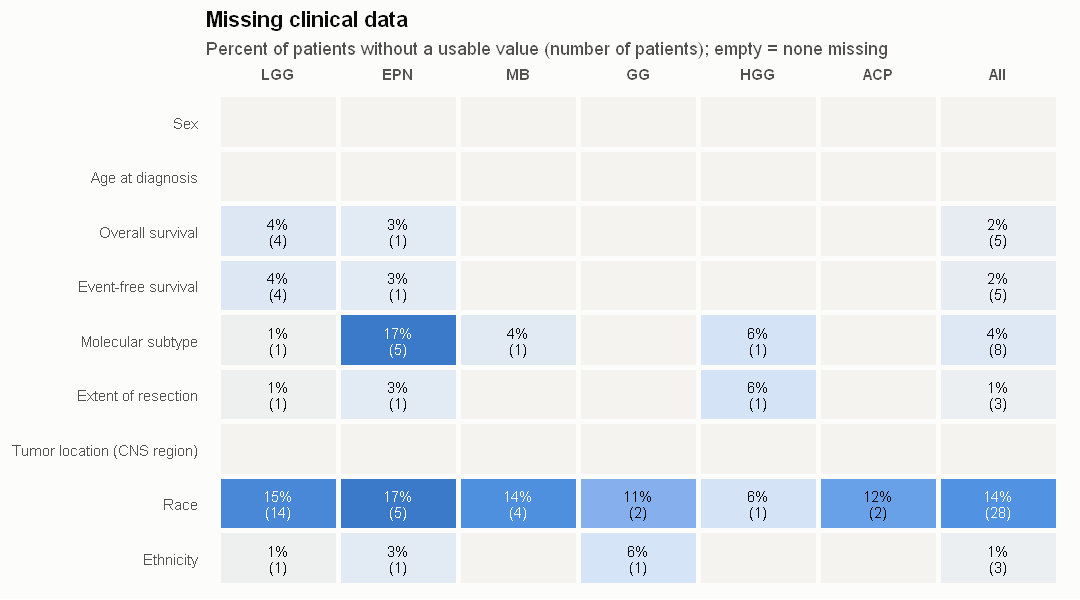

In [11]:
options(repr.plot.width = 9, repr.plot.height = 5)
unknown <- c("Reported Unknown", "Not Available", "Not Reported", "Unavailable")
has_value <- function(x) !is.na(x) & !(x %in% unknown) & !grepl("To be classified", x)
fields <- list(
  "Sex"                    = has_value(ct$sex),
  "Age at diagnosis"       = has_value(ct$age),
  "Overall survival"       = has_value(ct$t.os) & has_value(ct$os),
  "Event-free survival"    = has_value(ct$EFS_days) & has_value(ct$EFS_event_type),
  "Molecular subtype"      = has_value(ct$molecular_subtype),
  "Extent of resection"    = has_value(ct$extent_of_tumor_resection),
  "Tumor location (CNS region)" = has_value(ct$CNS_region),
  "Race"                   = has_value(ct$race),
  "Ethnicity"              = has_value(ct$ethnicity))
comp <- rbindlist(lapply(names(fields), function(f) {
  d <- data.table(type = c(SHORT[as.character(ct$histo)]), ok = fields[[f]])
  rbind(d[, .(missing = 100 * mean(!ok), n = sum(!ok)), by = type],
        data.table(type = "All", missing = 100 * mean(!d$ok), n = sum(!d$ok)))[, field := f]
}))
comp[, type := factor(type, levels = c(SHORT, "All"))]
comp[, field := factor(field, levels = rev(names(fields)))]
comp[, label := ifelse(n == 0, "", sprintf("%.0f%%\n(%d)", missing, n))]

ggplot(comp, aes(type, field, fill = missing)) +
  geom_tile(colour = "#fcfcfb", linewidth = 1.5) +
  geom_text(aes(label = label, colour = missing >= 13), size = 3.1, lineheight = 0.9) +
  scale_fill_gradientn(colours = c("#f4f3ef", "#cfe1f7", "#5598e7", "#1c5cab"), limits = c(0, 20), oob = scales::squish) +
  scale_colour_manual(values = c(`TRUE` = "#fcfcfb", `FALSE` = INK[["primary"]]), guide = "none") +
  scale_x_discrete(position = "top") +
  labs(title = "Missing clinical data", subtitle = "Percent of patients without a usable value (number of patients); empty = none missing",
       x = NULL, y = NULL) +
  theme_bp + theme(panel.grid.major.x = element_blank(), legend.position = "none", axis.text.x = element_text(face = "bold"))

### Survival by tumor type

Kaplan-Meier curves of overall survival, descriptive only (no tests). Ticks mark censored patients.

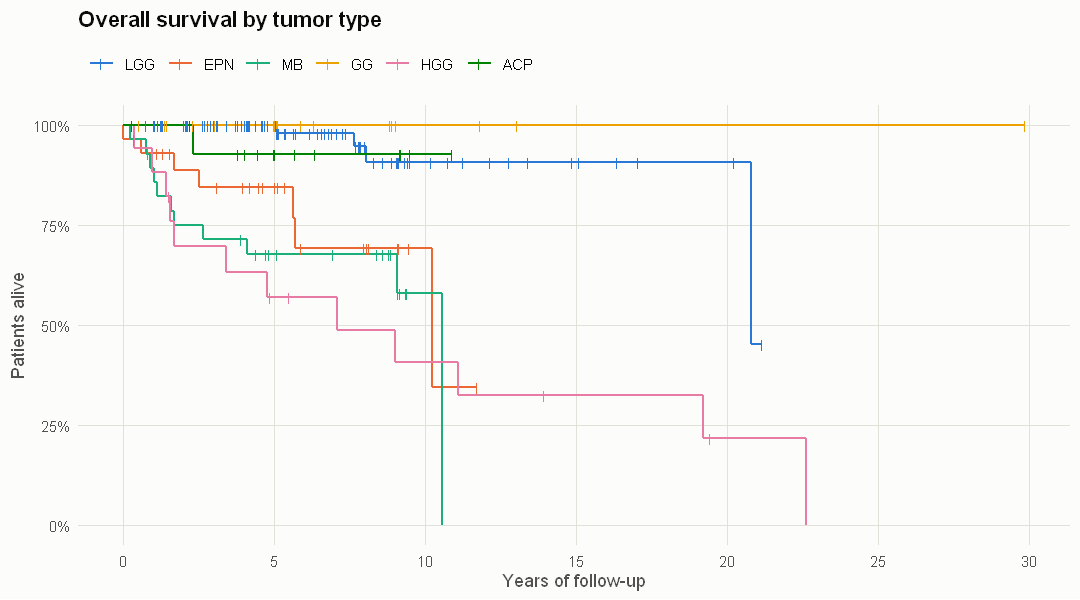

In [12]:
options(repr.plot.width = 9, repr.plot.height = 5)
ok <- !is.na(ct$t.os) & !is.na(ct$os)
fit <- survfit(Surv(ct$t.os[ok] / 12, ct$os[ok]) ~ as.character(ct$histo[ok]))
km <- data.table(type = sub("^.*=", "", rep(names(fit$strata), fit$strata)), time = fit$time, surv = fit$surv,
                 censored = fit$n.censor > 0)
km <- rbind(km[, .(time = 0, surv = 1, censored = FALSE), by = type], km)
km[, type := factor(type, levels = SIX_TYPES)]

ggplot(km, aes(time, surv, colour = type)) +
  geom_step(linewidth = 0.8) +
  geom_point(data = km[censored == TRUE], shape = 124, size = 2.2) +
  scale_colour_manual(values = TYPE_COLORS, labels = SHORT, name = NULL) +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1)) +
  scale_x_continuous(breaks = seq(0, 30, 5)) +
  guides(colour = guide_legend(nrow = 1)) +
  labs(title = "Overall survival by tumor type", x = "Years of follow-up", y = "Patients alive") +
  theme_bp + theme(panel.grid.major.y = element_line(colour = INK[["grid"]], linewidth = 0.3))

In [13]:
s <- summary(fit, times = 5, extend = TRUE)
data.table(tumor_type = sub("^.*=", "", as.character(s$strata)), patients = s$n, at_risk_5y = s$n.risk,
           OS_5y_95CI = sprintf("%.0f%% (%.0f-%.0f)", 100 * s$surv, 100 * s$lower, 100 * s$upper))[
  order(match(tumor_type, SIX_TYPES))]

tumor_type,patients,at_risk_5y,OS_5y_95CI
<chr>,<int>,<dbl>,<chr>
Low-grade glioma,89,50,100% (100-100)
Ependymoma,29,14,85% (72-100)
Medulloblastoma,28,13,68% (52-88)
Ganglioglioma,18,12,100% (100-100)
High-grade glioma,17,8,57% (37-87)
Adamantinomatous Craniopharyngioma,16,9,93% (80-100)


## 8. Save outputs

In [14]:
write.table(clin, file.path(OUT, "CLIN.csv"), quote = FALSE, sep = ";", col.names = TRUE, row.names = FALSE)
write.table(curation_tissue, file.path(root, "metadata", "curation_tissue.csv"), sep = ",", row.names = FALSE, col.names = TRUE)

# Read back the way the lab reads it (format_clin_cased_sequenced.R) to make sure the file is intact
back <- read.csv(file.path(OUT, "CLIN.csv"), sep = ";", stringsAsFactors = FALSE)
stopifnot(identical(dim(back), dim(clin)), identical(colnames(back), colnames(clin)))
cat("Saved", file.path(OUT, "CLIN.csv"), ":", nrow(back), "patients x", ncol(back), "columns\n")
cat("Saved", file.path(root, "metadata", "curation_tissue.csv"), "\n\n")
sessionInfo()

Saved D:\Bidirectional Promoters\bidirectional-promoters/data/procdata/02_clinical/CLIN.csv : 203 patients x 98 columns


Saved D:\Bidirectional Promoters\bidirectional-promoters/metadata/curation_tissue.csv 



R version 4.5.3 (2026-03-11 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_Canada.utf8  LC_CTYPE=English_Canada.utf8    LC_MONETARY=English_Canada.utf8
[4] LC_NUMERIC=C                    LC_TIME=English_Canada.utf8    

time zone: America/Toronto
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] AnnotationGx_0.99.3 stringr_1.6.0       jsonlite_2.0.0      tibble_3.3.1        survival_3.8-12    
[6] ggplot2_4.0.3       data.table_1.18.6.1

loaded via a namespace (and not attached):
 [1] Matrix_1.7-6       gtable_0.3.6       dplyr_1.2.1        compiler_4.5.3     crayon_1.5.3       tidyselect_1.2.1  
 [7] IRdisplay_1.1      splines_4.5.3      scales_1.4.0       uuid_1.2-2         fastmap_1.2.0      IRkernel_1.3.2    
[13] lattice_0.23-1     R6_2.6.1           labeling_0.4